# **Decision Trees and Cross Validation**

## Introduction

https://archive.ics.uci.edu/dataset/579/myocardial+infarction+complications


## Exploratory Data Analysis (EDA)

Missing values in this data ?

In [49]:
#Importing the relevant libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Importing the cross validation data split 
df_train = pd.read_csv("training_data.csv")
df_validate = pd.read_csv("validation_data.csv")
df_test = pd.read_csv("test_data.csv")

#Data set of merged training and validation for EDA purposes
#df_full = pd.concat([df_train, df_validate], ignore_index=True)
#df_full

df_train

,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,GB,SIM_GIPERT,DLIT_AG,ZSN_A,...,NOT_NA_2_n,NOT_NA_3_n,LID_S_n,B_BLOK_S_n,ANT_CA_S_n,GEPAR_S_n,ASP_S_n,TIKL_S_n,TRENT_S_n,mortality
0,75.0,0,1.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,...,0.0,NaN,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1
1,62.0,0,1.0,4.0,2.0,1.0,3.0,0.0,5.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0
2,52.0,0,0.0,0.0,0.0,0.0,3.0,0.0,6.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0
3,88.0,0,2.0,6.0,2.0,2.0,NaN,NaN,NaN,NaN,...,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,1
4,68.0,1,0.0,6.0,2.0,1.0,2.0,0.0,7.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1015,73.0,1,1.0,4.0,2.0,2.0,2.0,0.0,NaN,0.0,...,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0
1016,63.0,1,1.0,6.0,2.0,1.0,3.0,0.0,7.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0
1017,75.0,0,0.0,0.0,0.0,2.0,2.0,0.0,2.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0
1018,65.0,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0


Explanation

In [52]:
df_full[df_full['AGE'].isnull()]

,AGE,SEX,INF_ANAM,STENOK_AN,FK_STENOK,IBS_POST,GB,SIM_GIPERT,DLIT_AG,ZSN_A,...,NOT_NA_2_n,NOT_NA_3_n,LID_S_n,B_BLOK_S_n,ANT_CA_S_n,GEPAR_S_n,ASP_S_n,TIKL_S_n,TRENT_S_n,mortality
240,NaN,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0
850,NaN,0,0.0,6.0,2.0,1.0,2.0,0.0,7.0,0.0,...,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0
918,NaN,1,1.0,3.0,2.0,1.0,2.0,0.0,5.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0
926,NaN,1,0.0,3.0,2.0,2.0,2.0,0.0,7.0,1.0,...,1.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0
1046,NaN,1,0.0,3.0,2.0,2.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0
1283,NaN,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,1.0,1.0,1.0,0.0,1.0,0
1340,NaN,1,2.0,6.0,2.0,1.0,2.0,0.0,NaN,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0


In [51]:
#Assessing if there are any null values and the size of the data set
df_train.isnull().sum()


AGE           4
SEX           0
INF_ANAM      3
STENOK_AN    65
FK_STENOK    43
             ..
GEPAR_S_n     7
ASP_S_n       7
TIKL_S_n      8
TRENT_S_n     8
mortality     0
Length: 108, dtype: int64

In [50]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1020 entries, 0 to 1019
Columns: 108 entries, AGE to mortality
dtypes: float64(106), int64(2)
memory usage: 860.8 KB


 Explanation need some sort of imputation. Website where code is from says no missing values for age so explore this. 

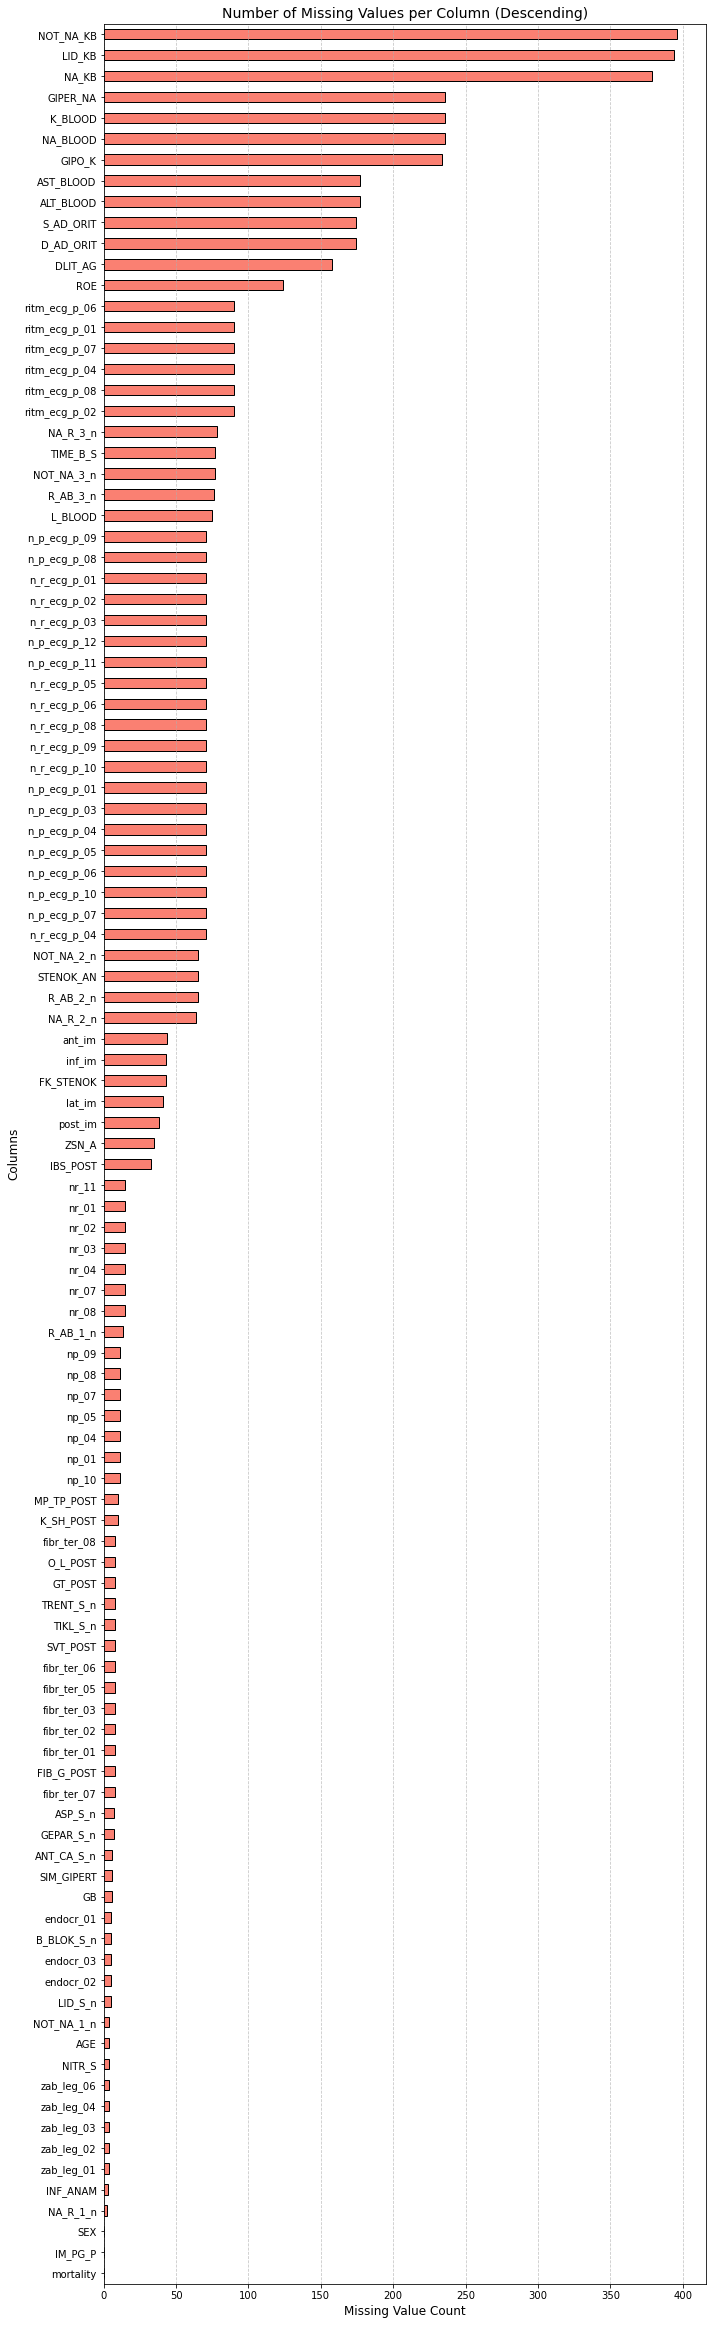

In [53]:
#PLOT OF MISSING VALUES

# 1. Calculate missing values and sort them in descending order
missing_values = df_train.isnull().sum().sort_values(ascending=False)

# Optional: Uncomment the line below if you only want to show columns that actually have missing values (> 0)
# missing_values = missing_values[missing_values > 0]

# 2. Create a horizontal bar plot and adjust figure height for readability
plt.figure(figsize=(10, max(6, len(missing_values) * 0.3))) # Dynamically scales height based on column count
missing_values.plot(kind='barh', color='salmon', edgecolor='black')

# 3. Customize the graph labels and layout
plt.title('Number of Missing Values per Column (Descending)', fontsize=14)
plt.xlabel('Missing Value Count', fontsize=12)
plt.ylabel('Columns', fontsize=12)
plt.gca().invert_yaxis()  # Puts the column with the highest missing values at the very top
plt.grid(axis='x', linestyle='--', alpha=0.7)

# 4. Display the plot
plt.tight_layout()
plt.show()

In [54]:
# Identify the top 3 columns with the most missing values
top_3_missing = df_train.isnull().sum().nlargest(3).index

print("Columns being dropped:")
print(top_3_missing)

# Drop these columns from both datasets
df_train = df_train.drop(columns=top_3_missing)
df_validate = df_validate.drop(columns=top_3_missing)

# Remove observations with missing AGE
df_train = df_train.dropna(subset=['AGE']).copy()
df_validate = df_validate.dropna(subset=['AGE']).copy()

# Check dimensions
print("Training:", df_train.shape)
print("Validation:", df_validate.shape)

Columns being dropped:
Index(['NOT_NA_KB', 'LID_KB', 'NA_KB'], dtype='object')
Training: (1016, 105)
Validation: (337, 105)


In [60]:
# Continuous numerical variables
numerical_cols = [
    'S_AD_ORIT',
    'D_AD_ORIT',
    'K_BLOOD',
    'NA_BLOOD',
    'ALT_BLOOD',
    'AST_BLOOD',
    'L_BLOOD',
    'ROE'
]

# Categorical variables
categorical_cols = [
    col for col in df_train.columns
    if col not in numerical_cols + ['AGE', 'mortality']
]

from sklearn.impute import SimpleImputer

# Initialise imputers
median_imputer = SimpleImputer(strategy='median')
mode_imputer = SimpleImputer(strategy='most_frequent')

# Median imputation for numerical variables
df_train[numerical_cols] = median_imputer.fit_transform(
    df_train[numerical_cols]
)

# Mode imputation for categorical variables
df_train[categorical_cols] = mode_imputer.fit_transform(
    df_train[categorical_cols]
)

# Check remaining missing values
print(df_train.isnull().sum().sum())


0


In [61]:
# Median imputation for validation data
df_validate[numerical_cols] = median_imputer.transform(
    df_validate[numerical_cols]
)

# Mode imputation for validation data
df_validate[categorical_cols] = mode_imputer.transform(
    df_validate[categorical_cols]
)

# Check remaining missing values
print(df_validate.isnull().sum().sum())

0


In [62]:
# Check remaining missing values
print("Training missing values:")
print(df_train.isnull().sum().sum())

print("Validation missing values:")
print(df_validate.isnull().sum().sum())

# Check dataset dimensions
print("Training shape:", df_train.shape)
print("Validation shape:", df_validate.shape)

Training missing values:
0
Validation missing values:
0
Training shape: (1016, 105)
Validation shape: (337, 105)


In [63]:
print(df_train['mortality'].isnull().sum())
print(df_validate['mortality'].isnull().sum())

0
0


Talk about the imputation. Drop null values for age. Drop top 3 worst columns


## Decision trees

A decision tree is a machine learning algorithm that can be used for classification. In this analysis....



To assess the quality of each model, 1-fold cross-validation is used  The model is trained using four folds and evaluated using the remaining fold. This process is repeated five times so that each fold is used as the validation set once.

The five accuracy values outputted in each section therefore represent the model's performance on five different subsets of the data. The mean accuracy provides an overall measure of predictive performance, while the standard deviation indicates how much the model's performance varies between folds.

The code used in this section is taken from the websites linked below. Variables have been altered to match this data set. 
https://www.datacamp.com/tutorial/decision-tree-classification-python
https://scikit-learn.org/stable/modules/cross_validation.html


### Decision tree 


In [119]:
# Load sklearn libraries
from sklearn.tree import DecisionTreeClassifier 
from sklearn.model_selection import cross_val_score

In [129]:
# Split dataset in features and target variable
features = []

# Features
X = df[features] 

# Target variable is the diagnosis
y = df.diagnosis  

# Create Decision Tree classifier object
clf = DecisionTreeClassifier()

# 5-fold cross-validation
# scoring='accuracy' calculates correct predictions / total predictions
scores = cross_val_score(clf, X, y, cv=5, scoring='accuracy')

#  Display the results
print("Accuracy scores for each fold:", scores)
print(f"Mean Accuracy: {scores.mean():.2f}")
print(f"Standard Deviation: {scores.std():.2f}")

Accuracy scores for each fold: [0.90350877 0.9122807  0.9122807  0.94736842 0.92920354]
Mean Accuracy: 0.92
Standard Deviation: 0.02


The decision tree correctly classifies approximately ...

## Visualising the decision trees
The advantage of decision trees is that they are easy to visualise because the classification process can be represented graphically. Visualising the trees also allows the individual decision rules used by the classifier to be seen.

Each node represents a decision based on one of the predictor variables. The value at which the data are split determines which observations follow each branch. The process continues until the observations reach a leaf node, where the model assigns a predicted class.

Below is the code used to visualise the decision tree of the mean measurements. The export_graphviz() function is used to convert each decision tree into a graphical representation. The feature names are included so that the variables used at each split can be identified, while the class names indicate the predicted tumour categories.

In [ ]:
#Displaying the decision tree for the mean characteristics
from sklearn.tree import export_graphviz
from io import StringIO                 
from IPython.display import Image  
import pydotplus

class_names = ['Malignant', 'Benign'] 
dot_data = StringIO()
export_graphviz(clf_mean, out_file=dot_data,  
                filled=True, rounded=True,
                special_characters=True, feature_names=features_mean, class_names=class_names) # Assuming class_names variable exists
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  
graph.write_png('breastcancer_mean.png')
Image(graph.create_png())

class_names = ['Malignant', 'Benign'] 
dot_data = StringIO()
export_graphviz(clf_se, out_file=dot_data,  
                filled=True, rounded=True,
                special_characters=True, feature_names=features_se, class_names=class_names) # Assuming class_names variable exists
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())  
graph.write_png('breastcancer_mean.png')
Image(graph.create_png())

### Decision tree of mean characteristics

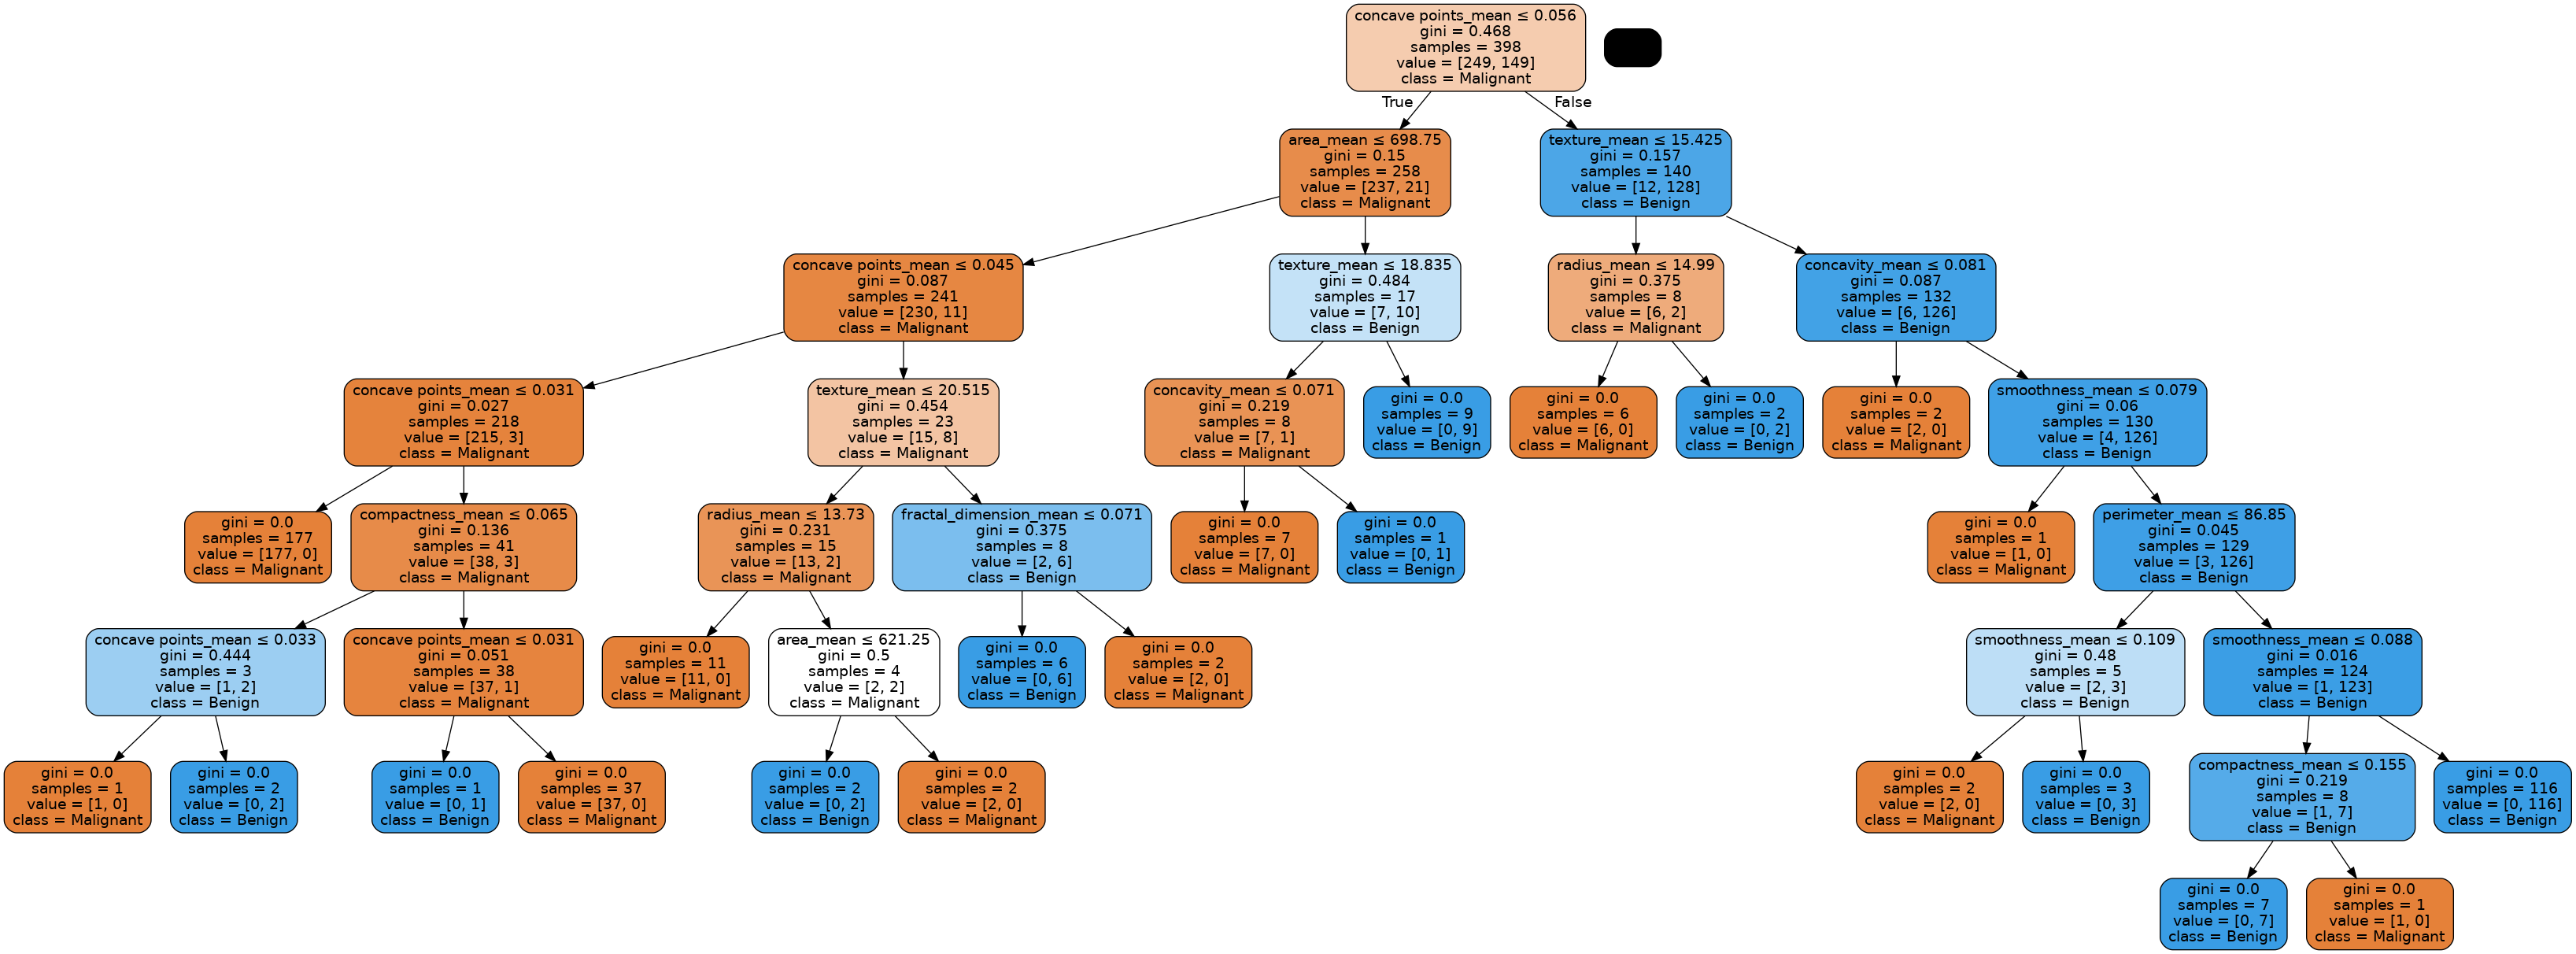

### Decision tree of standard error characteristics

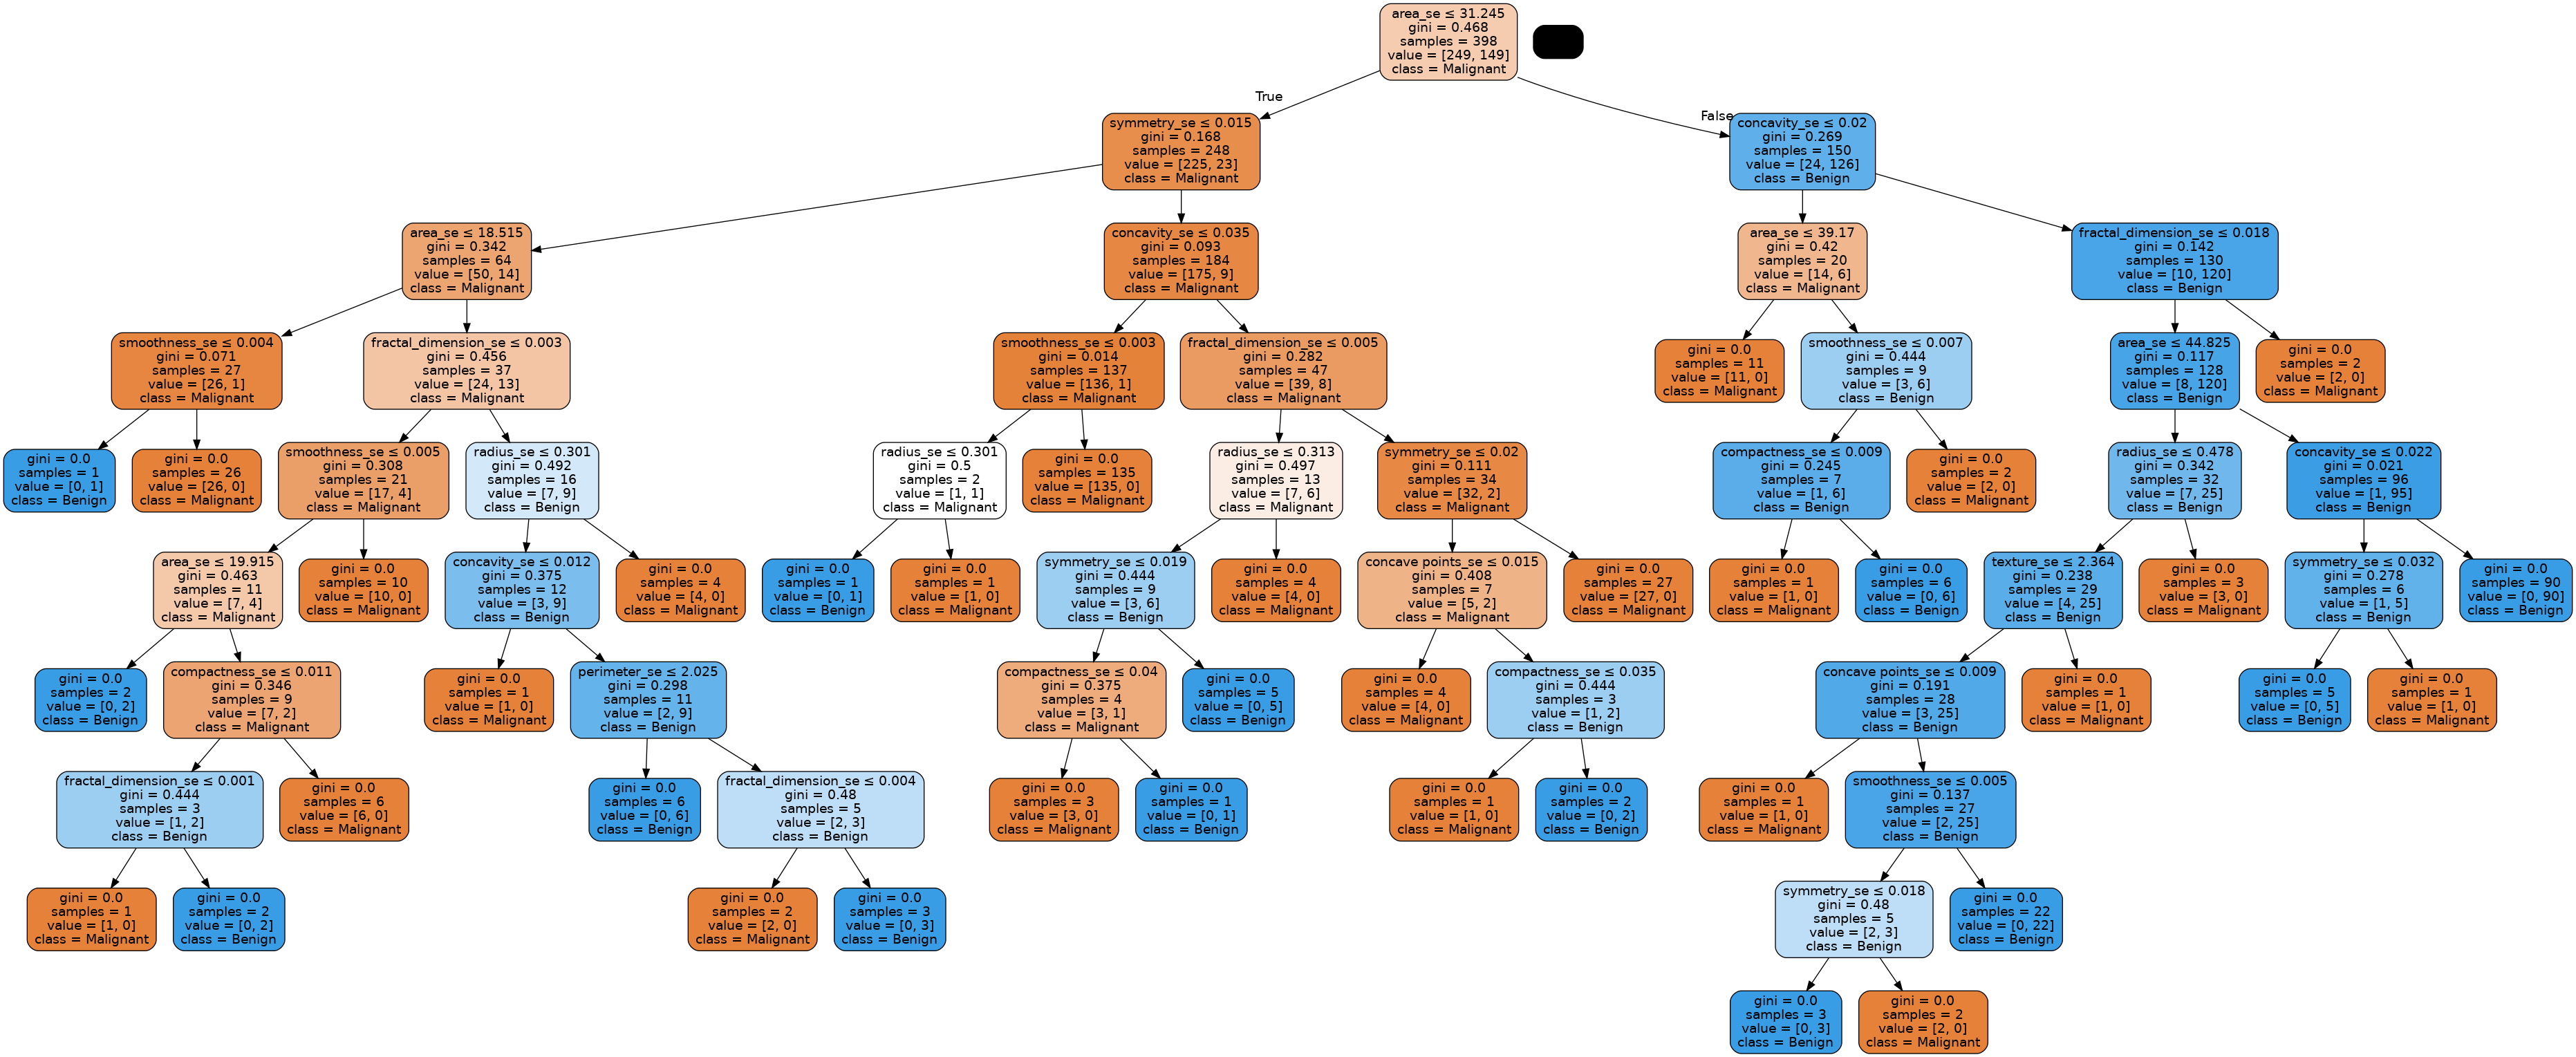

### Decision tree of worst characteristics

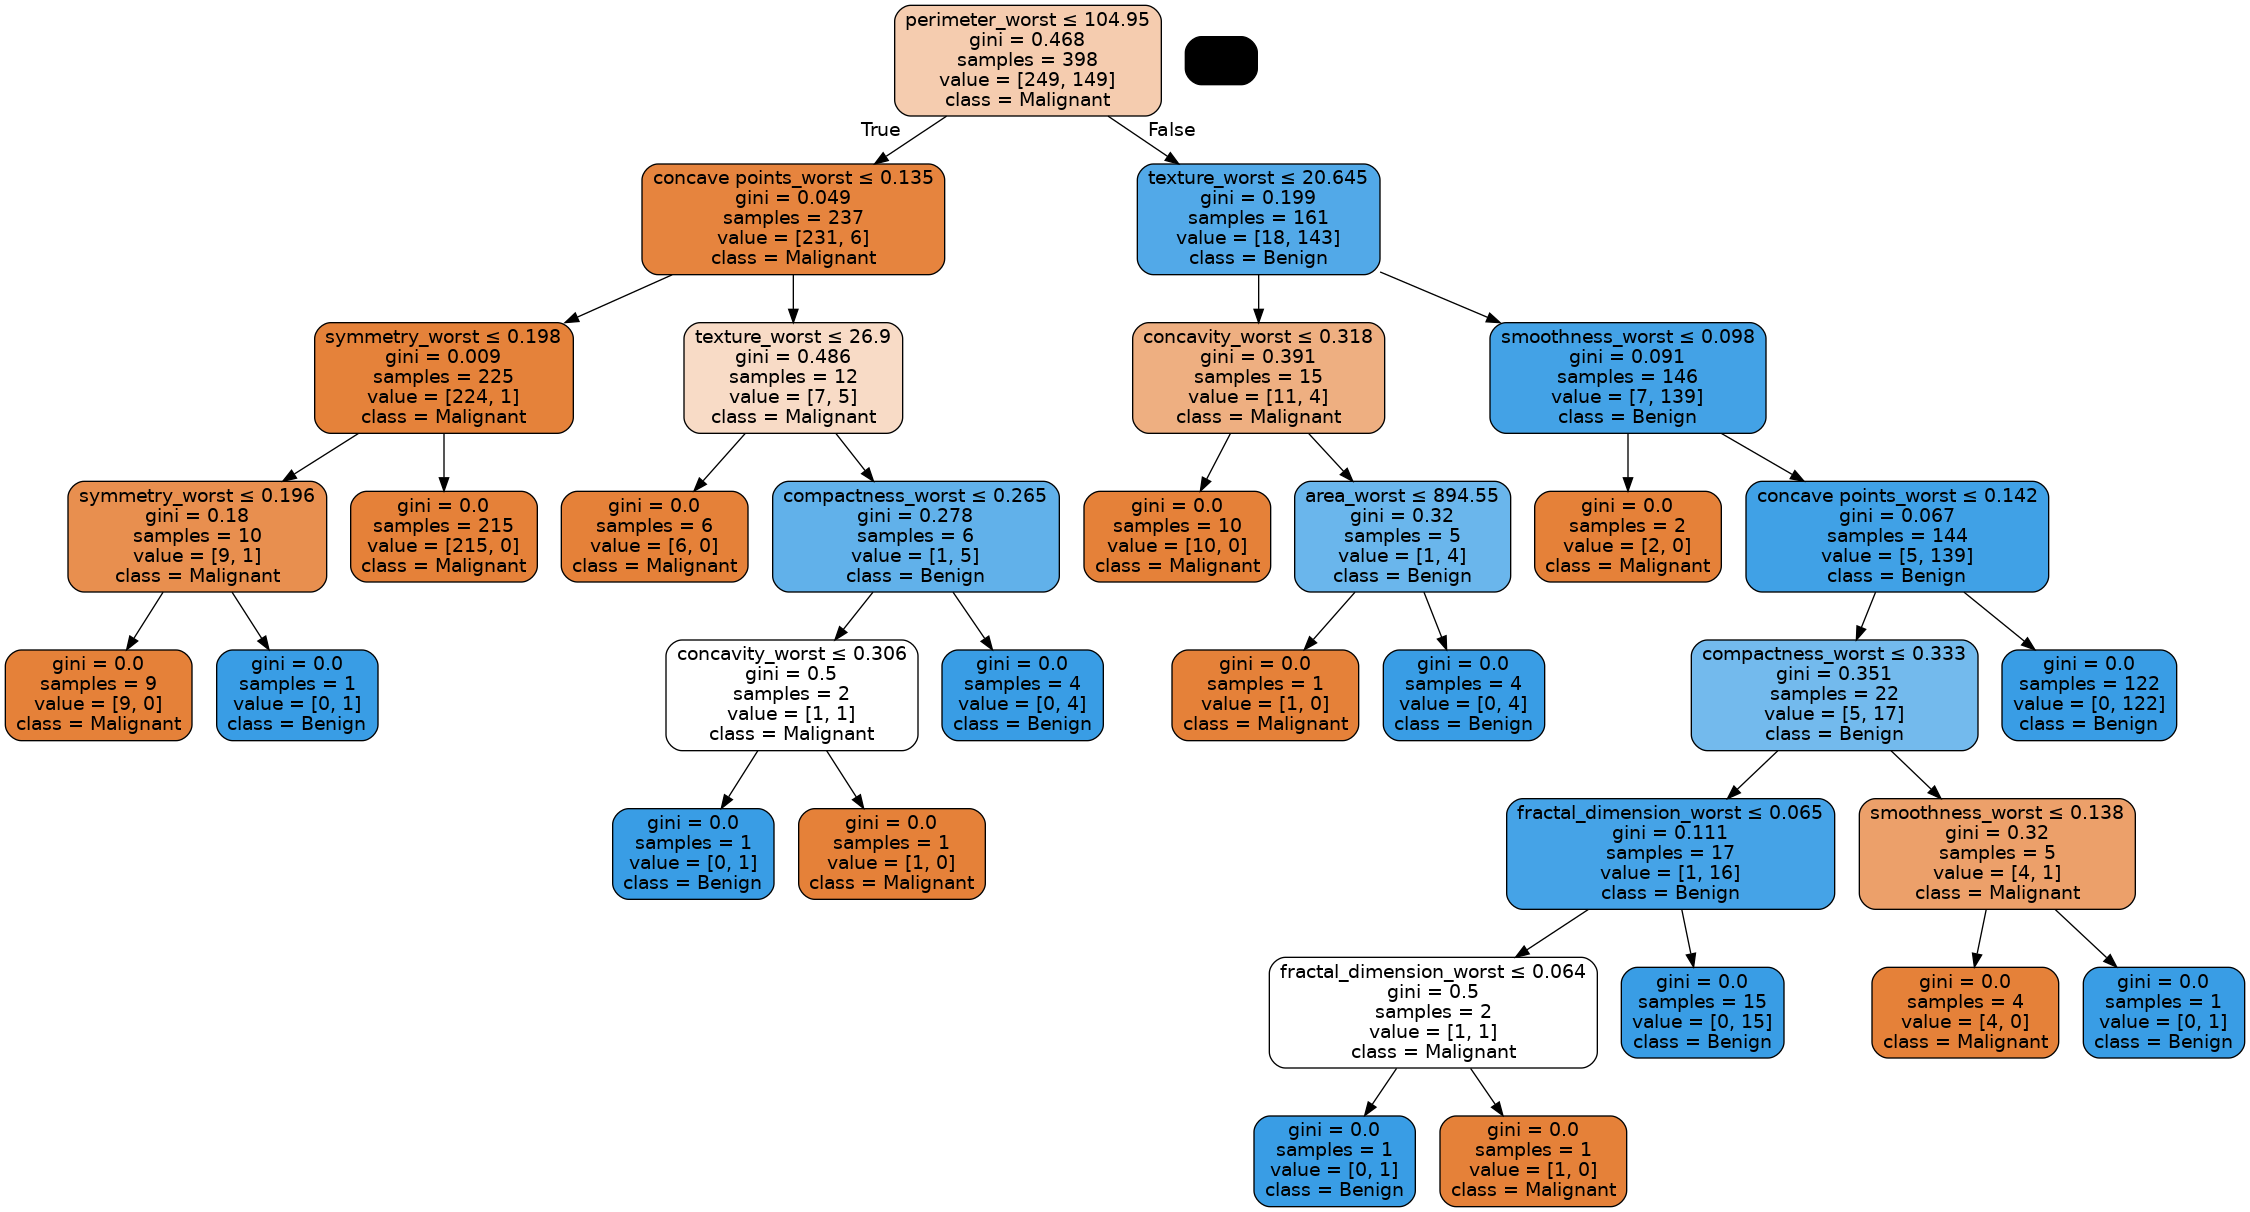

## Conclusion

This analysis investigated whether different groups of breast tumour characteristics could be used to predict whether a tumour is malignant or benign using decision tree classification. The results showed that the model based on the worst characteristics achieved the highest mean accuracy of 93%, followed by the model using the mean characteristics with an accuracy of 92%. The model using the standard error characteristics performed less well, achieving a mean accuracy of 83%. The relatively small standard deviations for the mean and worst models indicate that their performance was consistent across the five cross-validation folds.

Overall, the results suggest that the mean and particularly the worst measurements contain more useful information for distinguishing between malignant and benign tumours than the standard error measurements in this analysis. 
